# CSET343 – AI in Healthcare
## Lab Assignment 7: Grid Search on a Deep Learning Model (Scikit-learn + Keras)

**Dataset:** Pima Indians Diabetes — `mdssh784/pima-indians-diabetes-dataset` on Kaggle



### Setup — Install Required Packages

In [1]:

!pip install -q kagglehub scikeras tensorflow scikit-learn pandas numpy matplotlib seaborn


In [2]:
import os
import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from scikeras.wrappers import KerasClassifier

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)



## Task 1: Data Acquisition and Loading



In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mdssh784/pima-indians-diabetes-dataset")

print("Path to dataset files:", path)


/Users/pankurajasaivardhan/Documents/AIH/aih/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 8.91k/8.91k [00:00<00:00, 10.4MB/s]

Extracting files...
Path to dataset files: /Users/pankurajasaivardhan/.cache/kagglehub/datasets/mdssh784/pima-indians-diabetes-dataset/versions/1


In [4]:
csv_files = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)
print("CSV file(s) found:", csv_files)

df = pd.read_csv(csv_files[0])
print("Shape:", df.shape)
df.head()


CSV file(s) found: ['/Users/pankurajasaivardhan/.cache/kagglehub/datasets/mdssh784/pima-indians-diabetes-dataset/versions/1/diabetes.csv']
Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [5]:
df.info()
df.describe().T


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00



## Task 2: Data Preprocessing



In [6]:
# Detect the target column (commonly 'Outcome' in this dataset)
possible_targets = [c for c in df.columns if c.strip().lower() in ("outcome", "class", "target", "diabetes")]
target_col = possible_targets[0] if possible_targets else df.columns[-1]
print("Detected target column:", target_col)

df = df.rename(columns={target_col: "target"})
print(df["target"].value_counts())


Detected target column: Outcome
target
0    500
1    268
Name: count, dtype: int64


In [7]:
# This dataset famously encodes missing data as 0 in several physiologically-impossible
# columns (you can't have 0 glucose or 0 BMI) — treat those zeros as missing and impute.
zero_as_missing_cols = [c for c in ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"] if c in df.columns]
print("Columns where 0 is treated as missing:", zero_as_missing_cols)

for col in zero_as_missing_cols:
    df[col] = df[col].replace(0, np.nan)

print("\nMissing values per column:\n", df.isnull().sum()[df.isnull().sum() > 0])
print("\nDuplicate rows:", df.duplicated().sum())


Columns where 0 is treated as missing: ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

Missing values per column:
 Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Duplicate rows: 0


In [8]:
# Impute missing values with the median, drop duplicates
for col in zero_as_missing_cols:
    df[col] = df[col].fillna(df[col].median())

df = df.drop_duplicates()
print("Remaining missing values:", df.isnull().sum().sum())
print("Shape after cleaning:", df.shape)


Remaining missing values: 0
Shape after cleaning: (768, 9)


/var/folders/5c/8z7vyvz92nv0y0r62jyssfnc0000gn/T/ipykernel_24384/2672038164.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="target", data=df, palette="viridis")


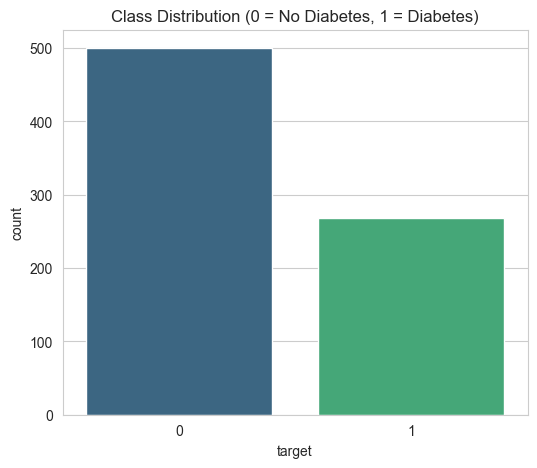

target
0    0.651
1    0.349
Name: proportion, dtype: float64


In [9]:
plt.figure(figsize=(6, 5))
sns.countplot(x="target", data=df, palette="viridis")
plt.title("Class Distribution (0 = No Diabetes, 1 = Diabetes)")
plt.show()
print(df["target"].value_counts(normalize=True).round(3))


In [10]:
feature_cols = [c for c in df.columns if c != "target"]

X = df[feature_cols].values
y = df["target"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train).astype(np.float32)
X_test_scaled = scaler.transform(X_test).astype(np.float32)

y_train = y_train.astype(np.float32)
y_test = y_test.astype(np.float32)

print("Train:", X_train_scaled.shape, "Test:", X_test_scaled.shape)
n_features = X_train_scaled.shape[1]


Train: (614, 8) Test: (154, 8)



## Task 3: Deep Learning Grid Search




### 3.0 Model-Building Function

In [11]:
def create_model(neurons=12, activation="relu", dropout_rate=0.0, init_mode="glorot_uniform", learning_rate=0.001):
    model = keras.Sequential([
        layers.Input(shape=(n_features,)),
        layers.Dense(neurons, activation=activation, kernel_initializer=init_mode),
        layers.Dropout(dropout_rate),
        layers.Dense(1, activation="sigmoid", kernel_initializer=init_mode),
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )
    return model

# Quick sanity check
create_model().summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12)             │           108 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 12)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            13 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121 (484.00 B)

 Trainable params: 121 (484.00 B)

 Non-trainable params: 0 (0.00 B)

In [12]:
# Hyperparameters found so far — updated after each grid search below
best_params = {
    "neurons": 12,
    "activation": "relu",
    "dropout_rate": 0.0,
    "init_mode": "glorot_uniform",
    "learning_rate": 0.001,
    "batch_size": 10,
    "epochs": 50,
}


### 3.1 Tune Batch Size and Epochs

In [13]:
model_1 = KerasClassifier(model=create_model, verbose=0, random_state=RANDOM_STATE)

param_grid_1 = {
    "batch_size": [10, 20, 40],
    "epochs": [30, 50, 100],
}

grid_1 = GridSearchCV(estimator=model_1, param_grid=param_grid_1, cv=3, scoring="accuracy", n_jobs=1)
grid_result_1 = grid_1.fit(X_train_scaled, y_train)

print(f"Best: {grid_result_1.best_score_:.4f} using {grid_result_1.best_params_}")
best_params.update(grid_result_1.best_params_)


E0000 00:00:1791140063.967621 1233929 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1791140069.767457 1233929 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

E0000 00:00:1791140093.932548 1233929 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
E0000 00:00:1791140099.049778 1233929 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

Best: 0.7883 using {'batch_size': 20, 'epochs': 100}


### 3.2 Tune Learning Rate

In [14]:
model_2 = KerasClassifier(
    model=create_model,
    batch_size=best_params["batch_size"],
    epochs=best_params["epochs"],
    verbose=0,
    random_state=RANDOM_STATE,
)

param_grid_2 = {
    "model__learning_rate": [0.1, 0.01, 0.001, 0.0001],
}

grid_2 = GridSearchCV(estimator=model_2, param_grid=param_grid_2, cv=3, scoring="accuracy", n_jobs=1)
grid_result_2 = grid_2.fit(X_train_scaled, y_train)

print(f"Best: {grid_result_2.best_score_:.4f} using {grid_result_2.best_params_}")
best_params["learning_rate"] = grid_result_2.best_params_["model__learning_rate"]


E0000 00:00:1791140104.834087 1233929 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
E0000 00:00:1791140109.839919 1233929 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

Best: 0.7883 using {'model__learning_rate': 0.001}


### 3.3 Tune Network Weight Initialization

In [15]:
model_3 = KerasClassifier(
    model=create_model,
    batch_size=best_params["batch_size"],
    epochs=best_params["epochs"],
    model__learning_rate=best_params["learning_rate"],
    verbose=0,
    random_state=RANDOM_STATE,
)

param_grid_3 = {
    "model__init_mode": [
        "uniform", "lecun_uniform", "normal", "glorot_uniform",
        "glorot_normal", "he_uniform", "he_normal",
    ],
}

grid_3 = GridSearchCV(estimator=model_3, param_grid=param_grid_3, cv=3, scoring="accuracy", n_jobs=1)
grid_result_3 = grid_3.fit(X_train_scaled, y_train)

print(f"Best: {grid_result_3.best_score_:.4f} using {grid_result_3.best_params_}")
best_params["init_mode"] = grid_result_3.best_params_["model__init_mode"]


E0000 00:00:1791140125.137861 1233929 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
E0000 00:00:1791140130.184829 1233929 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

Best: 0.7883 using {'model__init_mode': 'lecun_uniform'}


### 3.4 Tune Activation Function

In [16]:
model_4 = KerasClassifier(
    model=create_model,
    batch_size=best_params["batch_size"],
    epochs=best_params["epochs"],
    model__learning_rate=best_params["learning_rate"],
    model__init_mode=best_params["init_mode"],
    verbose=0,
    random_state=RANDOM_STATE,
)

param_grid_4 = {
    "model__activation": ["relu", "tanh", "sigmoid", "linear", "elu"],
}

grid_4 = GridSearchCV(estimator=model_4, param_grid=param_grid_4, cv=3, scoring="accuracy", n_jobs=1)
grid_result_4 = grid_4.fit(X_train_scaled, y_train)

print(f"Best: {grid_result_4.best_score_:.4f} using {grid_result_4.best_params_}")
best_params["activation"] = grid_result_4.best_params_["model__activation"]


E0000 00:00:1791140161.708016 1233929 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1791140166.712638 1233929 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

Best: 0.7883 using {'model__activation': 'relu'}


### 3.5 Tune Dropout Regularization

In [17]:
model_5 = KerasClassifier(
    model=create_model,
    batch_size=best_params["batch_size"],
    epochs=best_params["epochs"],
    model__learning_rate=best_params["learning_rate"],
    model__init_mode=best_params["init_mode"],
    model__activation=best_params["activation"],
    verbose=0,
    random_state=RANDOM_STATE,
)

param_grid_5 = {
    "model__dropout_rate": [0.0, 0.1, 0.2, 0.3, 0.4, 0.5],
}

grid_5 = GridSearchCV(estimator=model_5, param_grid=param_grid_5, cv=3, scoring="accuracy", n_jobs=1)
grid_result_5 = grid_5.fit(X_train_scaled, y_train)

print(f"Best: {grid_result_5.best_score_:.4f} using {grid_result_5.best_params_}")
best_params["dropout_rate"] = grid_result_5.best_params_["model__dropout_rate"]


E0000 00:00:1791140192.689923 1233929 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
E0000 00:00:1791140197.751191 1233929 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

Best: 0.7899 using {'model__dropout_rate': 0.3}


### 3.6 Tune Number of Neurons in the Hidden Layer

In [18]:
model_6 = KerasClassifier(
    model=create_model,
    batch_size=best_params["batch_size"],
    epochs=best_params["epochs"],
    model__learning_rate=best_params["learning_rate"],
    model__init_mode=best_params["init_mode"],
    model__activation=best_params["activation"],
    model__dropout_rate=best_params["dropout_rate"],
    verbose=0,
    random_state=RANDOM_STATE,
)

param_grid_6 = {
    "model__neurons": [4, 8, 12, 16, 24, 32],
}

grid_6 = GridSearchCV(estimator=model_6, param_grid=param_grid_6, cv=3, scoring="accuracy", n_jobs=1)
grid_result_6 = grid_6.fit(X_train_scaled, y_train)

print(f"Best: {grid_result_6.best_score_:.4f} using {grid_result_6.best_params_}")
best_params["neurons"] = grid_result_6.best_params_["model__neurons"]


E0000 00:00:1791140224.582357 1233929 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
E0000 00:00:1791140229.705733 1233929 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

Best: 0.7899 using {'model__neurons': 12}


### 3.7 Final Tuned Model — Train and Evaluate on the Test Set

In [19]:
print("Final selected hyperparameters:")
for k, v in best_params.items():
    print(f"  {k}: {v}")


Final selected hyperparameters:
  neurons: 12
  activation: relu
  dropout_rate: 0.3
  init_mode: lecun_uniform
  learning_rate: 0.001
  batch_size: 20
  epochs: 100


In [20]:
final_model = create_model(
    neurons=best_params["neurons"],
    activation=best_params["activation"],
    dropout_rate=best_params["dropout_rate"],
    init_mode=best_params["init_mode"],
    learning_rate=best_params["learning_rate"],
)

history = final_model.fit(
    X_train_scaled, y_train,
    validation_split=0.15,
    batch_size=best_params["batch_size"],
    epochs=best_params["epochs"],
    verbose=1,
)


Epoch 1/100


E0000 00:00:1791140256.226518 1233929 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4261 - loss: 0.8276 - val_accuracy: 0.4516 - val_loss: 0.7676
Epoch 2/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 884us/step - accuracy: 0.5067 - loss: 0.7457 - val_accuracy: 0.5376 - val_loss: 0.7183
Epoch 3/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 857us/step - accuracy: 0.5451 - loss: 0.7363 - val_accuracy: 0.5806 - val_loss: 0.6817
Epoch 4/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 810us/step - accuracy: 0.5681 - loss: 0.6981 - val_accuracy: 0.5806 - val_loss: 0.6520
Epoch 5/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 788us/step - accuracy: 0.6276 - loss: 0.6554 - val_accuracy: 0.6882 - val_loss: 0.6287
Epoch 6/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 787us/step - accuracy: 0.6200 - loss: 0.6517 - val_accuracy: 0.7312 - val_loss: 0.6086
Epoch 7/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 778us/step - accuracy: 0.6814 - loss: 0.6307 - val_accuracy: 0.7634 - val_loss: 0.5904
Epoch 8/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 777us/step - accuracy: 0.6929 - loss: 0.6239 - val_accuracy: 0.7742 -

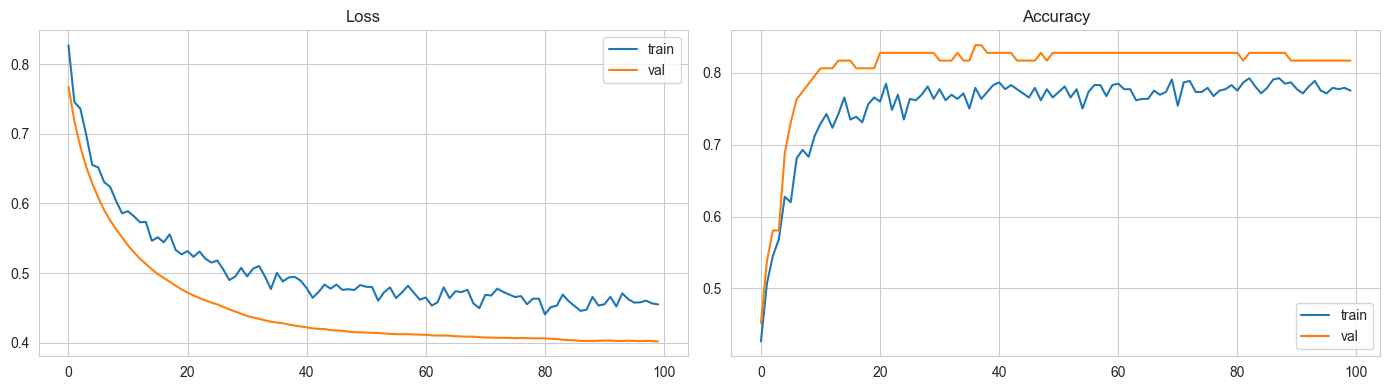

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(history.history["loss"], label="train")
axes[0].plot(history.history["val_loss"], label="val")
axes[0].set_title("Loss"); axes[0].legend()

axes[1].plot(history.history["accuracy"], label="train")
axes[1].plot(history.history["val_accuracy"], label="val")
axes[1].set_title("Accuracy"); axes[1].legend()

plt.tight_layout()
plt.show()


In [22]:
y_proba = final_model.predict(X_test_scaled, verbose=0).ravel()
y_pred = (y_proba >= 0.5).astype(int)

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
    "AUROC": roc_auc_score(y_test, y_proba),
}

for k, v in metrics.items():
    print(f"{k}: {v:.4f}")

print("\n" + classification_report(y_test, y_pred, target_names=["No Diabetes", "Diabetes"], zero_division=0))


Accuracy: 0.7273
Precision: 0.6250
Recall: 0.5556
F1-score: 0.5882
AUROC: 0.8056

              precision    recall  f1-score   support

 No Diabetes       0.77      0.82      0.80       100
    Diabetes       0.62      0.56      0.59        54

    accuracy                           0.73       154
   macro avg       0.70      0.69      0.69       154
weighted avg       0.72      0.73      0.72       154



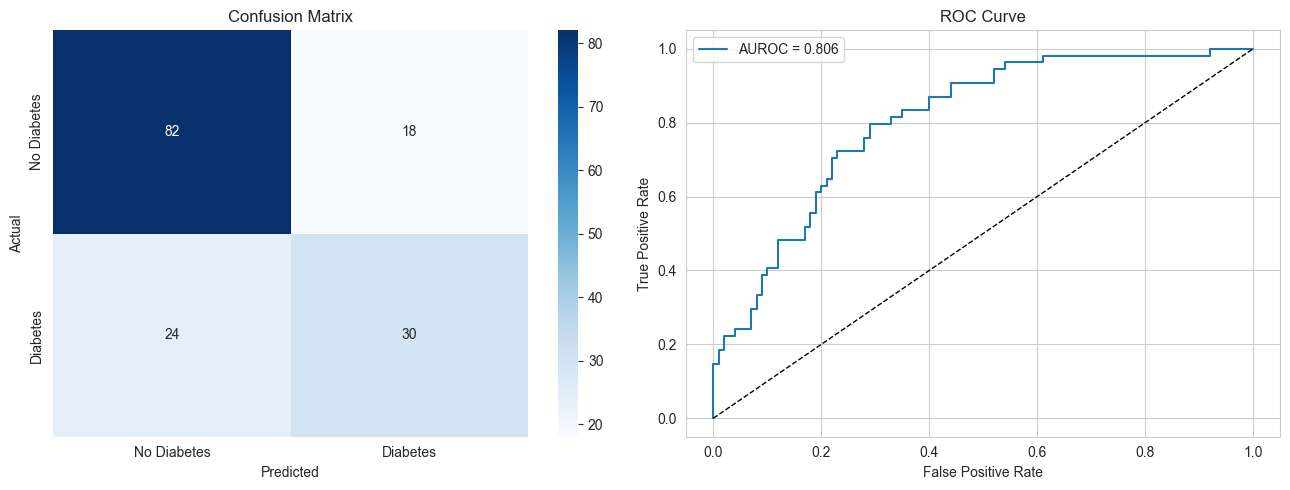

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["No Diabetes", "Diabetes"], yticklabels=["No Diabetes", "Diabetes"])
axes[0].set_title("Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[1].plot(fpr, tpr, label=f"AUROC = {metrics['AUROC']:.3f}")
axes[1].plot([0, 1], [0, 1], "k--", linewidth=1)
axes[1].set_title("ROC Curve")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend()

plt.tight_layout()
plt.show()
